Lab 02 — Web Scraping, Feature Engineering and Exploratory Data Analysis

Instructor Name: Attique-ur-Rehman

Student Name: Zoha Adnan

Sap Id: 70177706

In [8]:
!pip install scikit-learn Pillow numpy pandas matplotlib


In [9]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 1. Define Sample Text Data (our "corpus") based on the supplied photograph
documents = [
    "A person is standing on a sunny balcony.",
    "The photograph shows trees, mountains, and buildings in the background.",
    "The sky is bright blue with a few white clouds.",
    "The person is wearing a denim jacket, a light shirt, blue jeans, and white shoes.",
    "The balcony has a tiled floor, a wooden roof, and a red metal railing."
]

print("--- Raw Text Documents ---")
for i, doc in enumerate(documents):
    print(f"Doc {i+1}: {doc}")

--- Raw Text Documents ---
Doc 1: A person is standing on a sunny balcony.
Doc 2: The photograph shows trees, mountains, and buildings in the background.
Doc 3: The sky is bright blue with a few white clouds.
Doc 4: The person is wearing a denim jacket, a light shirt, blue jeans, and white shoes.
Doc 5: The balcony has a tiled floor, a wooden roof, and a red metal railing.


In [10]:
# 2. Apply Feature Engineering: CountVectorizer (Bag-of-Words)
#    CountVectorizer performs tokenization AND vocabulary building in one step.
vectorizer = CountVectorizer()

# fit_transform learns the vocabulary and converts the documents into feature vectors
X_text = vectorizer.fit_transform(documents)

# 3. Analyze the Results
feature_names = vectorizer.get_feature_names_out()
text_matrix = X_text.toarray()

print("--- Bag-of-Words (BoW) Transformation ---")
print(f"Vocabulary (Features): {feature_names}")
print(f"Shape of Feature Matrix: {text_matrix.shape}   (documents x unique terms)")

--- Bag-of-Words (BoW) Transformation ---
Vocabulary (Features): ['and' 'background' 'balcony' 'blue' 'bright' 'buildings' 'clouds' 'denim'
 'few' 'floor' 'has' 'in' 'is' 'jacket' 'jeans' 'light' 'metal'
 'mountains' 'on' 'person' 'photograph' 'railing' 'red' 'roof' 'shirt'
 'shoes' 'shows' 'sky' 'standing' 'sunny' 'the' 'tiled' 'trees' 'wearing'
 'white' 'with' 'wooden']
Shape of Feature Matrix: (5, 37)   (documents x unique terms)


In [11]:
# A DataFrame view, purely so the matrix is readable
df_text = pd.DataFrame(text_matrix, columns=feature_names,
                       index=[f"Doc {i+1}" for i in range(len(documents))])

print("BoW Numerical Feature Matrix (Machine Understandable Format):\n")
display(df_text)

BoW Numerical Feature Matrix (Machine Understandable Format):



,and,background,balcony,blue,bright,buildings,clouds,denim,few,floor,...,sky,standing,sunny,the,tiled,trees,wearing,white,with,wooden
Doc 1,0,0,1,0,0,0,0,0,0,0,...,0,1,1,0,0,0,0,0,0,0
Doc 2,1,1,0,0,0,1,0,0,0,0,...,0,0,0,2,0,1,0,0,0,0
Doc 3,0,0,0,1,1,0,1,0,1,0,...,1,0,0,1,0,0,0,1,1,0
Doc 4,1,0,0,1,0,0,0,1,0,0,...,0,0,0,1,0,0,1,1,0,0
Doc 5,1,0,1,0,0,0,0,0,0,1,...,0,0,0,1,1,0,0,0,0,1


In [12]:
# Prove the two silent decisions to yourself rather than taking them on trust.

print("Is 'a' in the vocabulary? ", 'a' in feature_names)
print("Is 'the' in the vocabulary?", 'the' in feature_names)
print()
print("Default token pattern :", vectorizer.token_pattern)
print("Lowercase enabled     :", vectorizer.lowercase)
print()
print("The token pattern requires 2+ word characters, which is why 'a' is dropped.")

Is 'a' in the vocabulary?  False
Is 'the' in the vocabulary? True

Default token pattern : (?u)\b\w\w+\b
Lowercase enabled     : True

The token pattern requires 2+ word characters, which is why 'a' is dropped.


In [13]:
# Sparsity: how much of this matrix is zero? This is the defining property of BoW.
total_cells = text_matrix.size
zero_cells = (text_matrix == 0).sum()

print(f"Matrix cells : {total_cells}")
print(f"Zero cells   : {zero_cells}")
print(f"Sparsity     : {zero_cells / total_cells:.1%}")
print()
print("With a real corpus of 20,000 documents this figure exceeds 99%,")
print("which is why scikit-learn returns a SPARSE matrix, not a dense array.")
print("Type returned by fit_transform:", type(X_text))

Matrix cells : 185
Zero cells   : 137
Sparsity     : 74.1%

With a real corpus of 20,000 documents this figure exceeds 99%,
which is why scikit-learn returns a SPARSE matrix, not a dense array.
Type returned by fit_transform: <class 'scipy.sparse._csr.csr_matrix'>


In [14]:
# Select the photograph from your computer (works in Jupyter Notebook, not only Google Colab).
# A file-selection window will open. If it cannot open, enter the image path manually.

try:
    import tkinter as tk
    from tkinter import filedialog

    root = tk.Tk()
    root.withdraw()
    root.attributes("-topmost", True)
    image_file_path = filedialog.askopenfilename(
        title="Select your photograph",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp *.webp"),
            ("All files", "*.*")
        ]
    )
    root.destroy()
except Exception:
    image_file_path = ""

if not image_file_path:
    image_file_path = input(
        "Enter the full path of your photograph (for example: C:/Users/YourName/Pictures/photo.jpg): "
    ).strip().strip('"').strip("'")

if not image_file_path:
    raise ValueError("No image was selected. Please run this cell again and select your photograph.")

print("Using:", image_file_path)

Using: C:/Users/LENOVO/Downloads/WhatsApp Image 2026-11-10 at 9.38.43 PM.jpeg


In [15]:
import numpy as np
from PIL import Image
import os

# Use the image selected in the upload cell above.
if not os.path.exists(image_file_path):
    raise FileNotFoundError(f"Image file not found: {image_file_path}. Run the image-selection cell again and choose the correct photograph.")

original_image = Image.open(image_file_path).convert('RGB')
original_image_array = np.array(original_image)

h, w, c = original_image_array.shape
print(f"--- Loaded Image: {image_file_path} ---")
print(f"Original Image Size (H, W, Channels): {original_image_array.shape}")
print(f"Total Features (Pixels) in RGB: {h * w * c}")

--- Loaded Image: C:/Users/LENOVO/Downloads/WhatsApp Image 2026-11-10 at 9.38.43 PM.jpeg ---
Original Image Size (H, W, Channels): (1600, 1200, 3)
Total Features (Pixels) in RGB: 5760000


--- Loaded Image: C:/Users/LENOVO/Downloads/WhatsApp Image 2026-11-10 at 9.38.43 PM.jpeg ---
Original Image Size (H, W, Channels): (1600, 1200, 3)
Total Features (Pixels) in RGB: 5760000


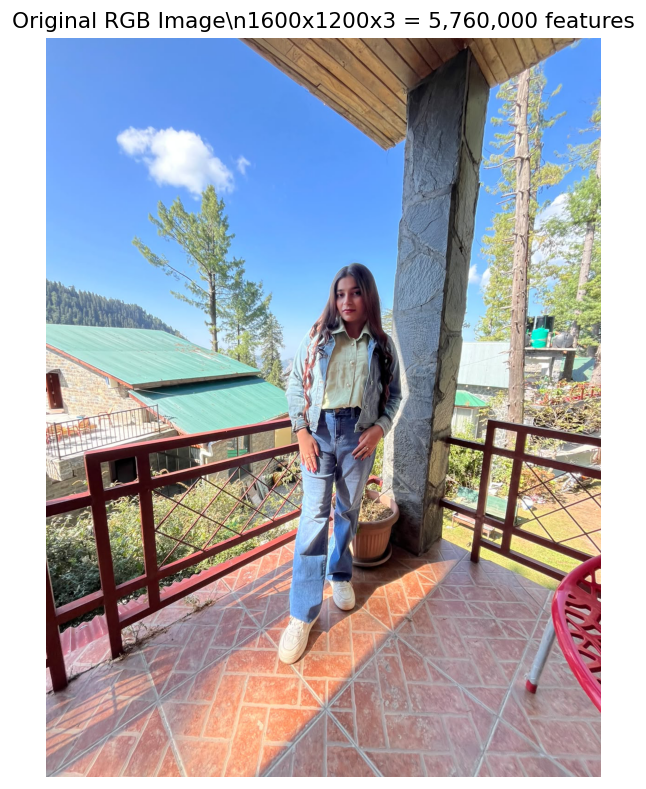

In [16]:
import numpy as np
from PIL import Image
import os
import matplotlib.pyplot as plt

# Display the same photograph uploaded in cell 7.
if not os.path.exists(image_file_path):
    raise FileNotFoundError(f"Image file not found: {image_file_path}. Run the image-selection cell again and choose the correct photograph.")

original_image = Image.open(image_file_path).convert('RGB')
original_image_array = np.array(original_image)

h, w, c = original_image_array.shape
print(f"--- Loaded Image: {image_file_path} ---")
print(f"Original Image Size (H, W, Channels): {original_image_array.shape}")
print(f"Total Features (Pixels) in RGB: {h * w * c}")

# --- Display the original photograph ---
plt.figure(figsize=(8, 8), dpi=120)
plt.imshow(original_image)
plt.title(f"Original RGB Image\\n{h}x{w}x{c} = {h*w*c:,} features", fontsize=13)
plt.axis('off')
plt.show()

--- Grayscale Conversion (Feature Reduction) ---
Grayscale Image Size (H, W): (1600, 1200)
Total Features (Pixels) after Grayscale: 1920000

Reduction factor: 3x fewer features


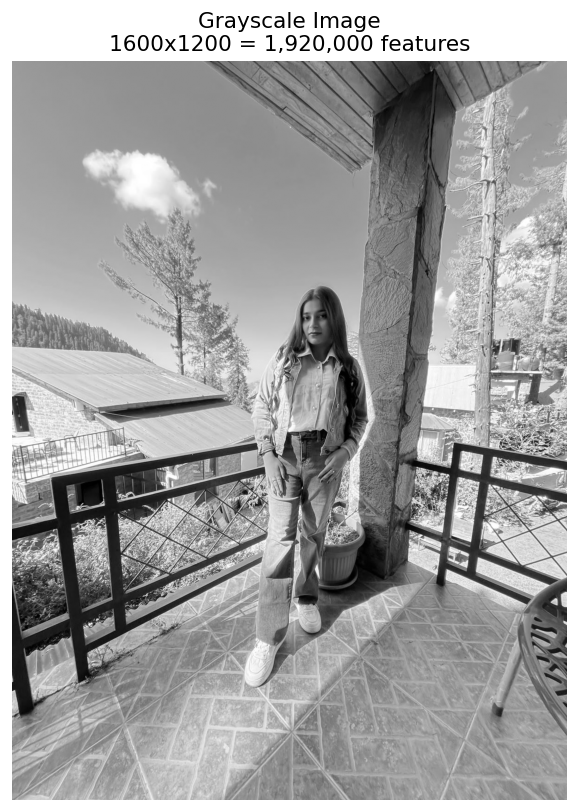

In [17]:
grayscale_image = original_image.convert('L')
grayscale_array = np.array(grayscale_image)

print("--- Grayscale Conversion (Feature Reduction) ---")
print(f"Grayscale Image Size (H, W): {grayscale_array.shape}")
print(f"Total Features (Pixels) after Grayscale: {grayscale_array.size}")
print()
print(f"Reduction factor: {(h * w * c) / grayscale_array.size:.0f}x fewer features")

# --- Display the grayscale image ---
plt.figure(figsize=(8, 8), dpi=120)
plt.imshow(grayscale_image, cmap='gray')
plt.title(f"Grayscale Image\n{h}x{w} = {h*w:,} features", fontsize=13)
plt.axis('off')
plt.show()

--- Pixel Flattening (Vectorization) ---
Flattened Feature Vector Shape: (1920000,)

First 10 Features (Pixel Values) in Machine Understandable Format:
[155 155 155 155 155 155 155 155 154 154]

Data Type of Final Features: uint8


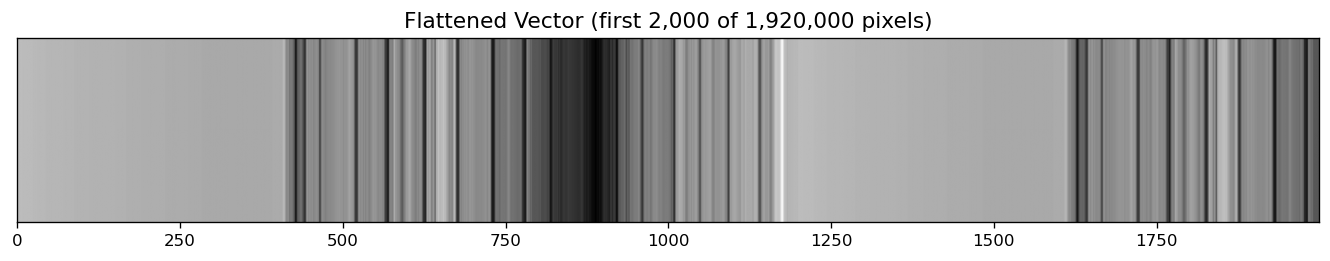

In [18]:
flattened_features = grayscale_array.flatten()

print("--- Pixel Flattening (Vectorization) ---")
print(f"Flattened Feature Vector Shape: {flattened_features.shape}")
print()
print("First 10 Features (Pixel Values) in Machine Understandable Format:")
print(flattened_features[:10])
print()
print(f"Data Type of Final Features: {flattened_features.dtype}")

# --- Display the flattened vector as one row of pixels ---
plt.figure(figsize=(14, 2), dpi=120)
plt.imshow(flattened_features[:2000].reshape(1, -1), cmap='gray', aspect='auto')
plt.title(f"Flattened Vector (first 2,000 of {flattened_features.size:,} pixels)", fontsize=13)
plt.yticks([])
plt.show()

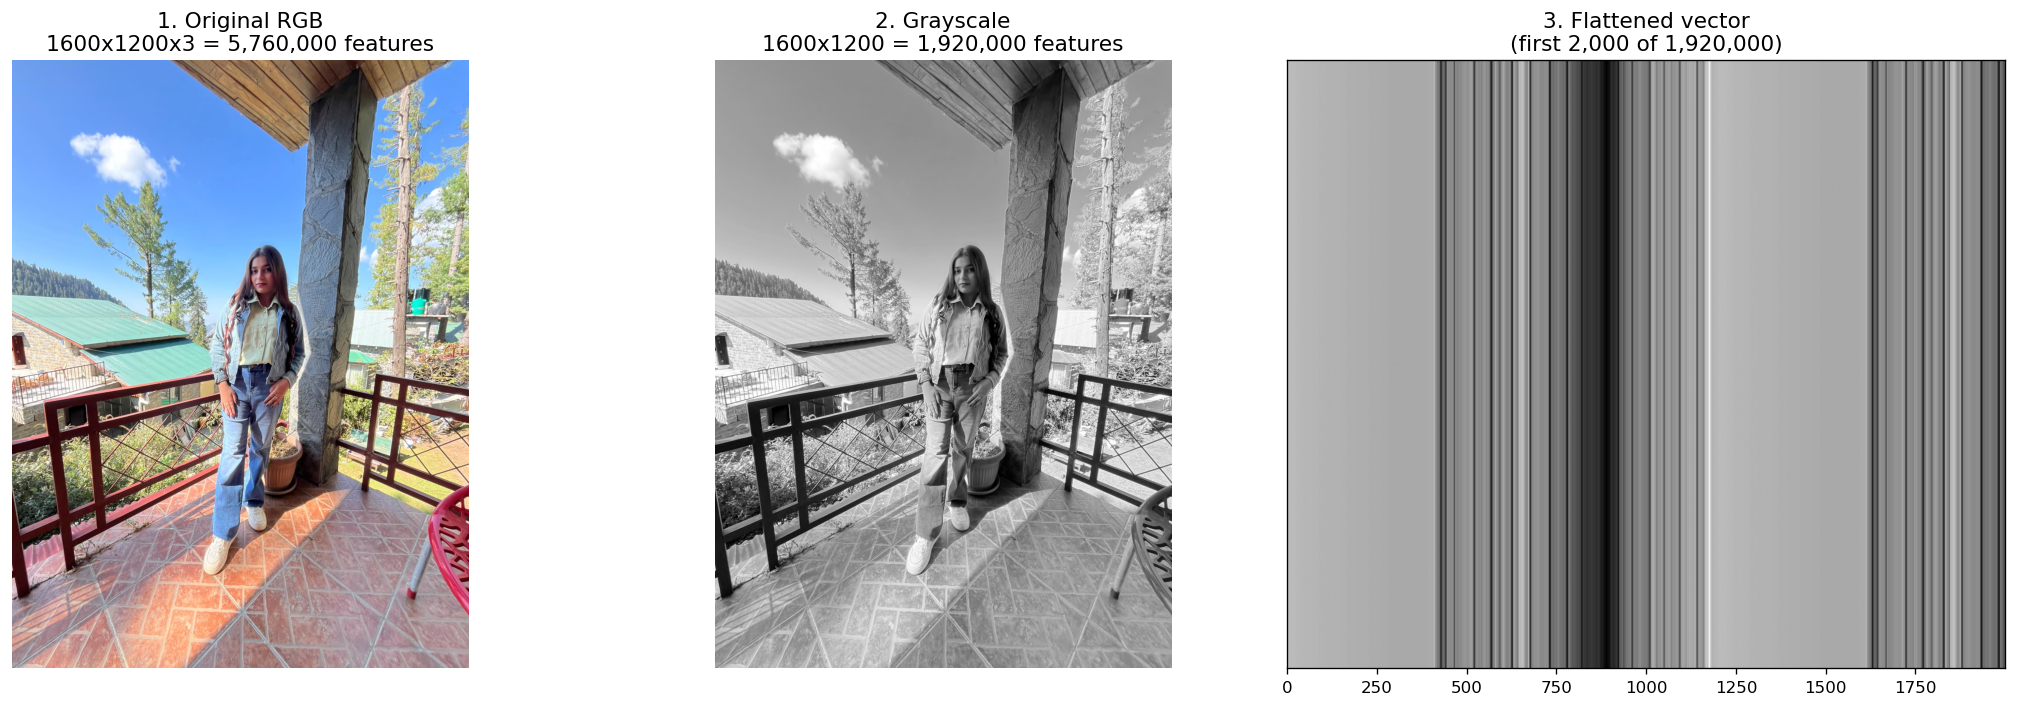

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=120)

axes[0].imshow(original_image)
axes[0].set_title(f"1. Original RGB\n{h}x{w}x{c} = {h*w*c:,} features", fontsize=13)
axes[0].axis('off')

axes[1].imshow(grayscale_image, cmap='gray')
axes[1].set_title(f"2. Grayscale\n{h}x{w} = {h*w:,} features", fontsize=13)
axes[1].axis('off')

axes[2].imshow(flattened_features[:2000].reshape(1, -1), cmap='gray', aspect='auto')
axes[2].set_title(f"3. Flattened vector\n(first 2,000 of {flattened_features.size:,})", fontsize=13)
axes[2].set_yticks([])

plt.tight_layout()
plt.show()

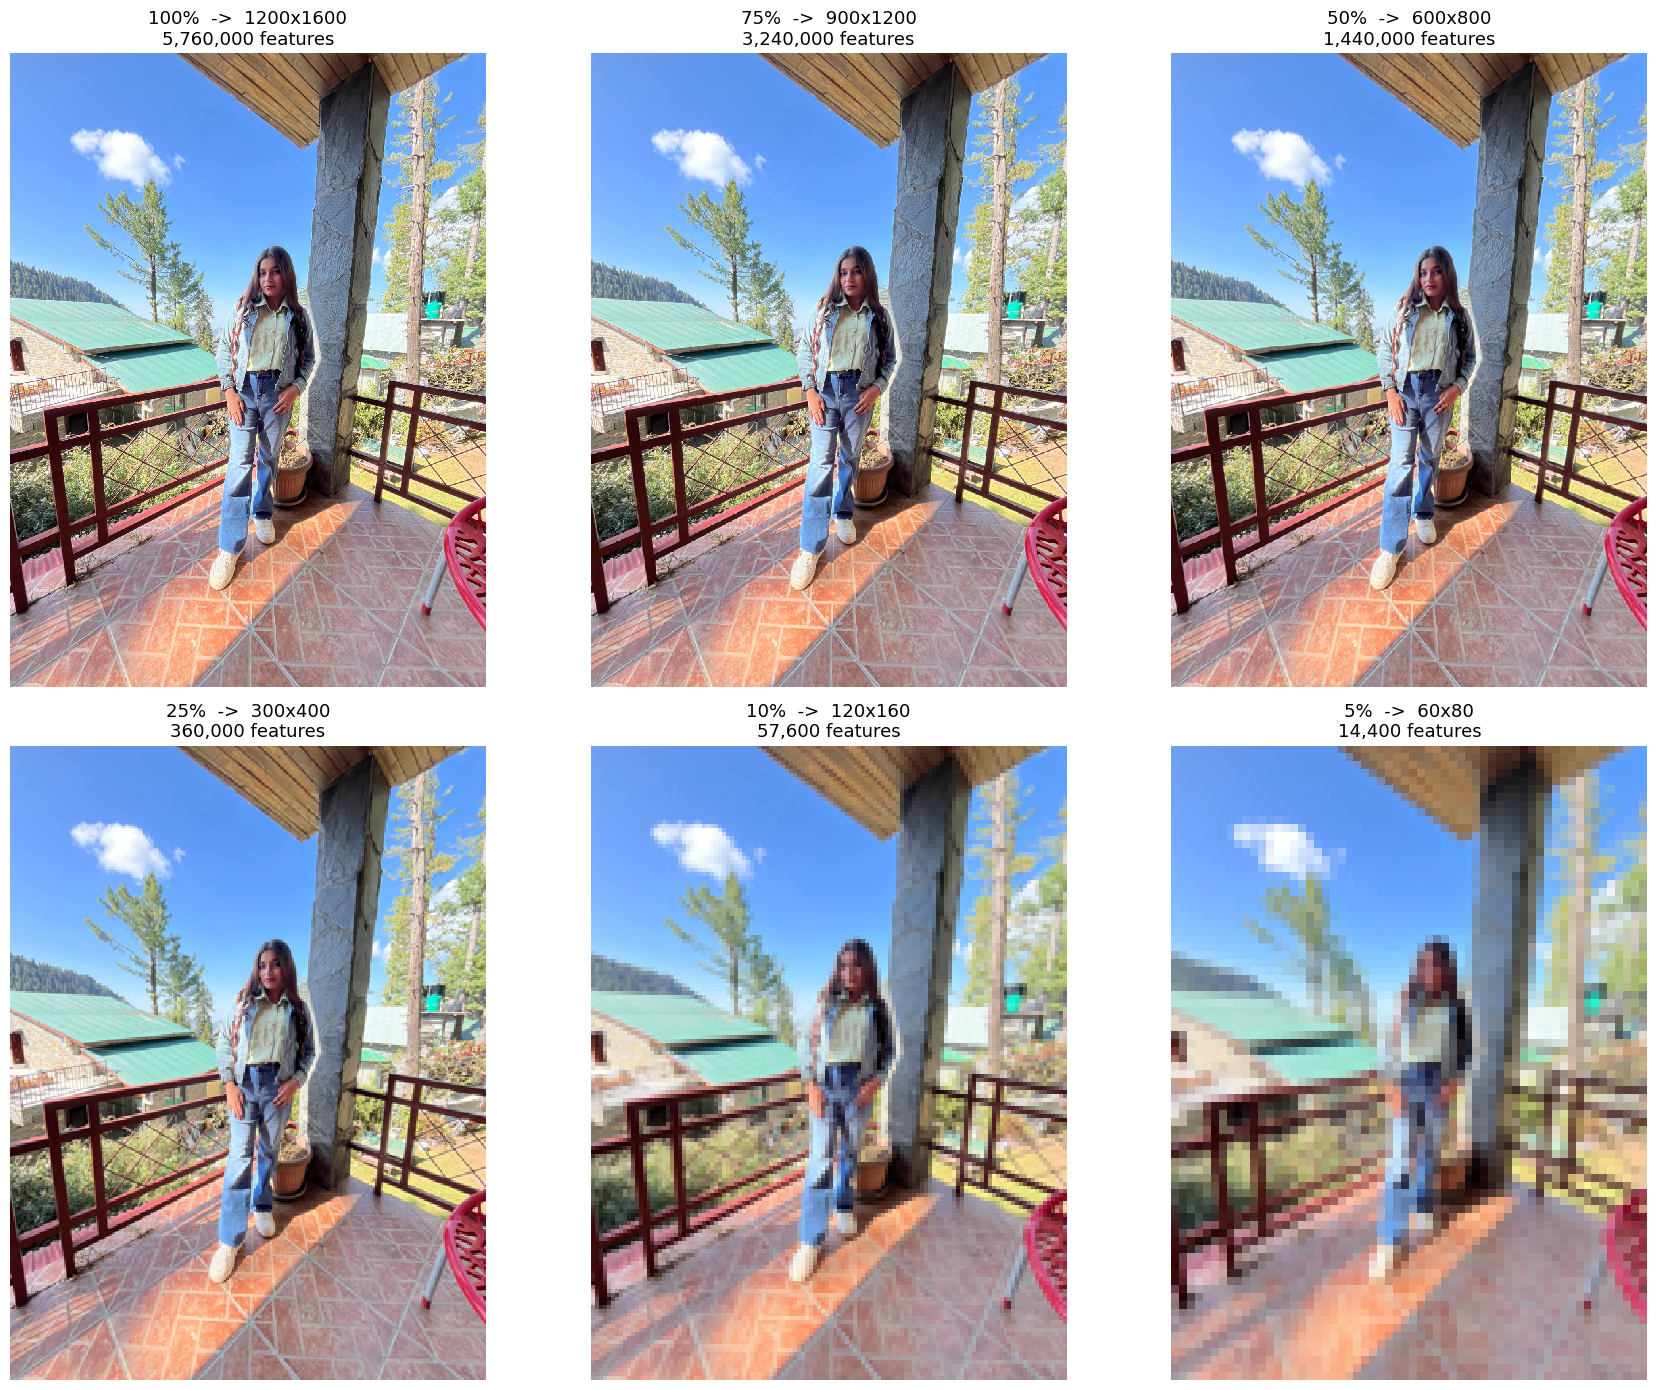

In [20]:
percentages = [100, 75, 50, 25, 10, 5]

fig, axes = plt.subplots(2, 3, figsize=(18, 14), dpi=100)
for ax, p in zip(axes.flatten(), percentages):
    new_w, new_h = max(1, int(w * p / 100)), max(1, int(h * p / 100))
    small = original_image.resize((new_w, new_h))
    # scale back up to original size WITHOUT smoothing, so lost pixels show as blocks
    shown = small.resize((w, h), Image.NEAREST)
    ax.imshow(shown, interpolation='nearest')
    ax.set_title(f"{p}%  ->  {new_w}x{new_h}\n{new_w*new_h*3:,} features", fontsize=13)
    ax.axis('off')

plt.tight_layout()
plt.show()

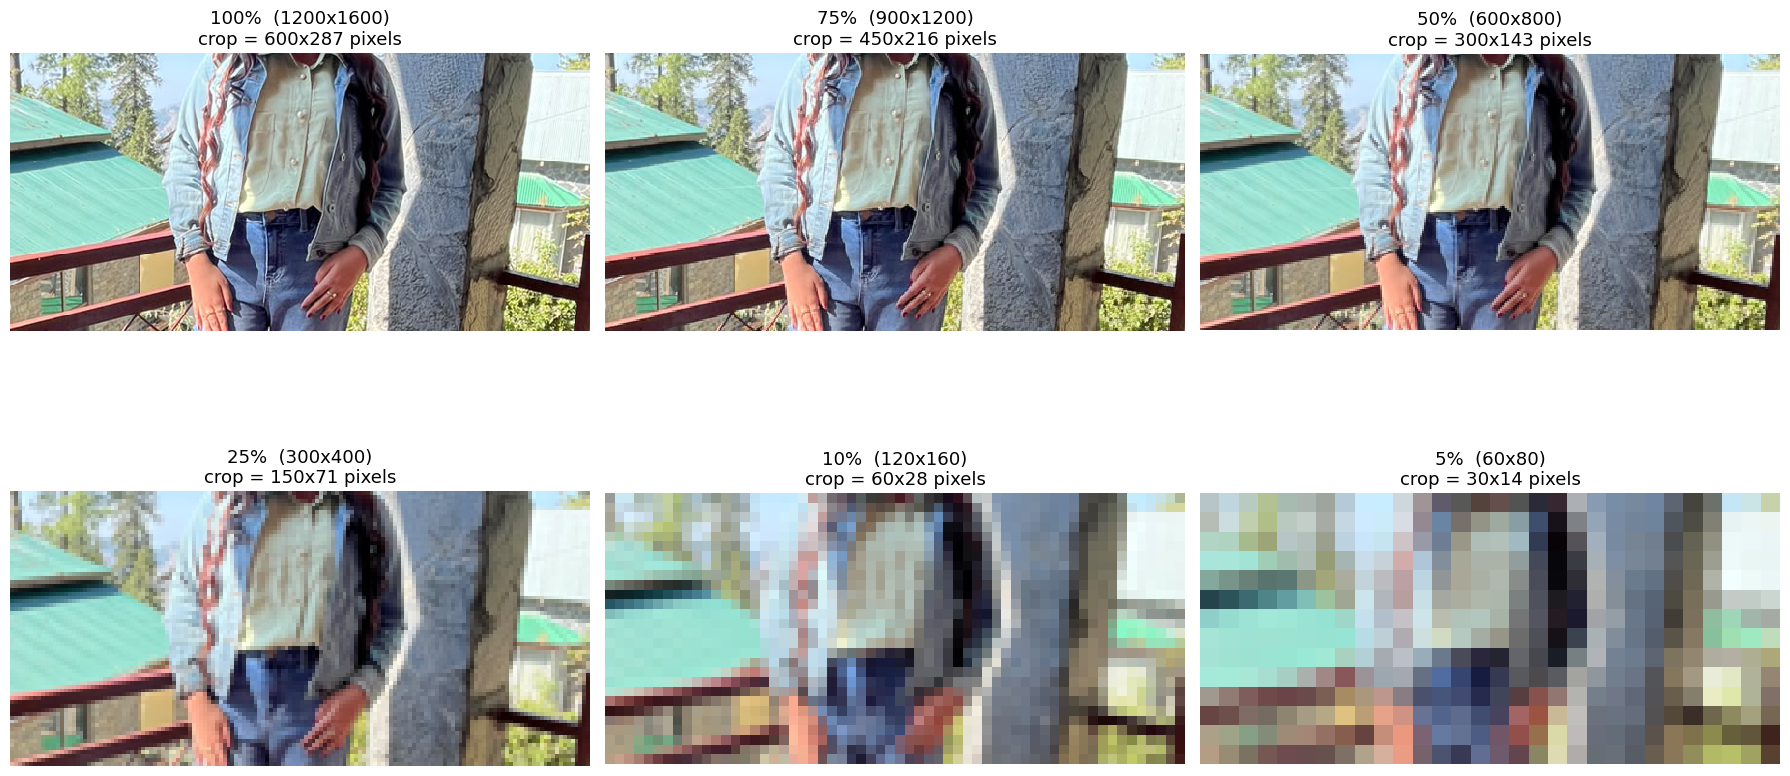

In [21]:
percentages = [100, 75, 50, 25, 10, 5]

fig, axes = plt.subplots(2, 3, figsize=(18, 10), dpi=100)
for ax, p in zip(axes.flatten(), percentages):
    new_w, new_h = max(1, int(w * p / 100)), max(1, int(h * p / 100))
    small = original_image.resize((new_w, new_h))
    # same relative region from every size (adjust these fractions to move the crop)
    box = (int(0.30 * new_w), int(0.40 * new_h), int(0.80 * new_w), int(0.58 * new_h))
    crop = small.crop(box)
    ax.imshow(crop, interpolation='nearest')
    ax.set_title(f"{p}%  ({new_w}x{new_h})\ncrop = {crop.size[0]}x{crop.size[1]} pixels", fontsize=13)
    ax.axis('off')

plt.tight_layout()
plt.show()

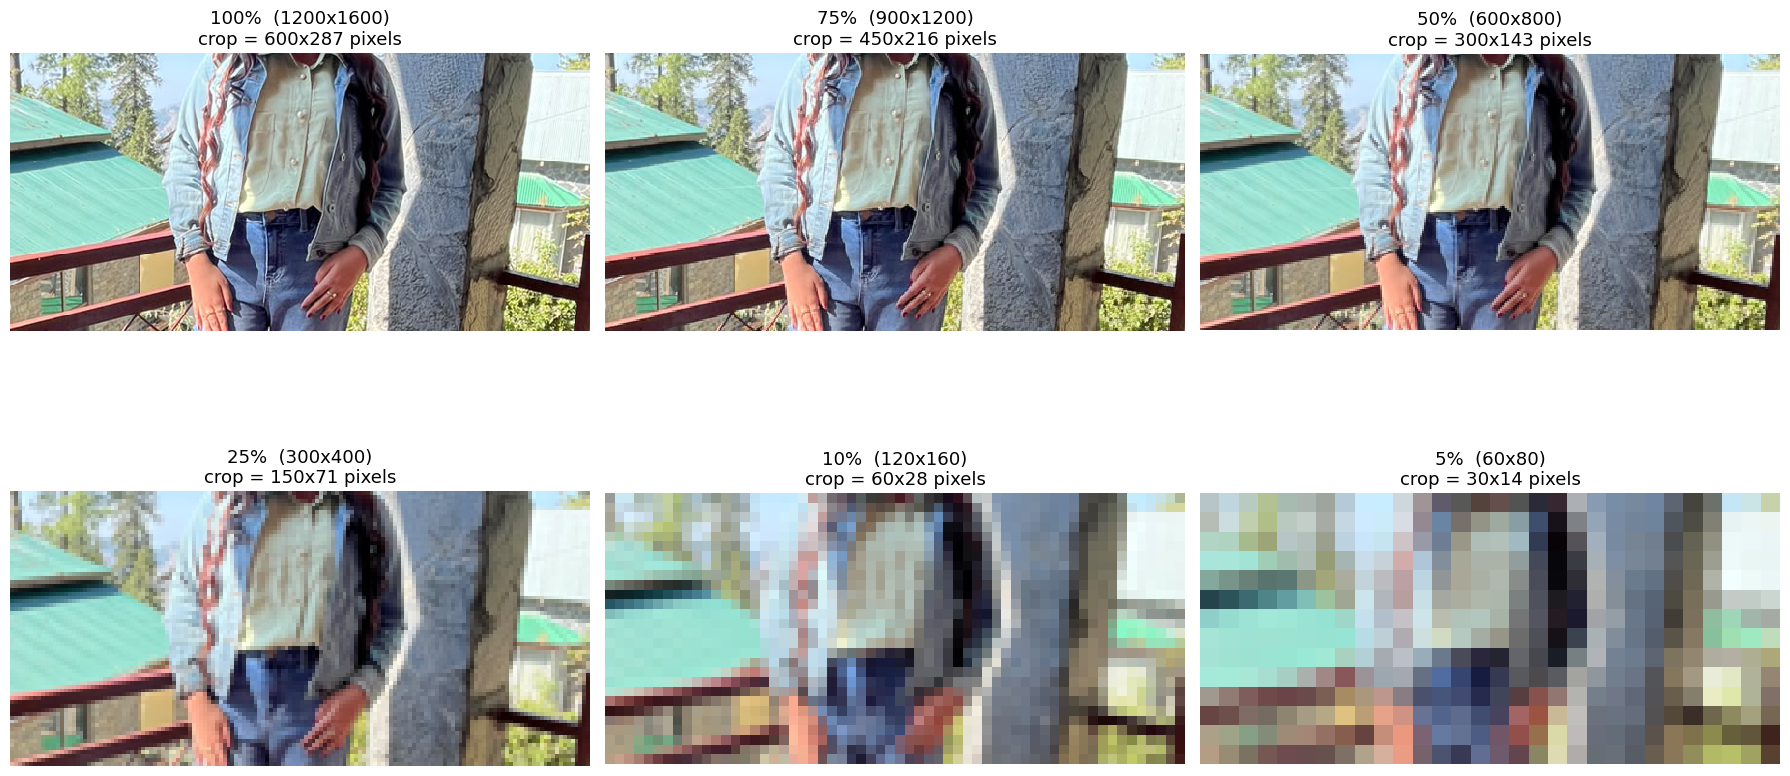

In [22]:
percentages = [100, 75, 50, 25, 10, 5]

fig, axes = plt.subplots(2, 3, figsize=(18, 10), dpi=100)
for ax, p in zip(axes.flatten(), percentages):
    new_w, new_h = max(1, int(w * p / 100)), max(1, int(h * p / 100))
    small = original_image.resize((new_w, new_h))
    # same relative region from every size (adjust these fractions to move the crop)
    box = (int(0.30 * new_w), int(0.40 * new_h), int(0.80 * new_w), int(0.58 * new_h))
    crop = small.crop(box)
    ax.imshow(crop, interpolation='nearest')
    ax.set_title(f"{p}%  ({new_w}x{new_h})\ncrop = {crop.size[0]}x{crop.size[1]} pixels", fontsize=13)
    ax.axis('off')

plt.tight_layout()
plt.show()